# Olist E-commerce: Predicting Customer Dissatisfaction

The SQL/EDA part found that delivery delay correlates with review score. Here I test if it can actually predict a bad review (score ≤ 3) before it's written, useful because support could step in early instead of finding out after the fact.

Steps: load data → build features/target → train/test split → Logistic Regression baseline → Random Forest → compare → explain with SHAP → look at one prediction in detail.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
os.makedirs("plots", exist_ok=True)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, 
classification_report, RocCurveDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)

In [2]:
df = pd.read_csv("olist_complete_analytical_dataset.csv")

assert df["order_id"].is_unique
print(f"{df.shape[0]:,} orders, {df.shape[1]} columns")
df.head()

96,478 orders, 18 columns


,order_id,customer_id,customer_city,customer_state,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,review_score,review_creation_date,review_answer_timestamp,product_id,product_category_name,product_weight_g,price,freight_value,n_items,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,sao paulo,SP,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18 00:00:00,4.0,2017-10-11 00:00:00,2017-10-12 03:43:48,87285b34884572647811a353c7ac498a,utilidades_domesticas,500.0,29.99,8.72,1,1.0,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,barreiras,BA,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13 00:00:00,4.0,2018-08-08 00:00:00,2018-08-08 18:37:50,595fac2a385ac33a80bd5114aec74eb8,perfumaria,400.0,118.70,22.76,1,1.0,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,vianopolis,GO,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04 00:00:00,5.0,2018-08-18 00:00:00,2018-08-22 19:07:58,aa4383b373c6aca5d8797843e5594415,automotivo,420.0,159.90,19.22,1,3.0,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,sao goncalo do amarante,RN,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15 00:00:00,5.0,2017-12-03 00:00:00,2017-12-05 19:21:58,d0b61bfb1de832b15ba9d266ca96e5b0,pet_shop,450.0,45.00,27.20,1,1.0,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,santo andre,SP,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26 00:00:00,5.0,2018-02-17 00:00:00,2018-02-18 13:02:51,65266b2da20d04dbe00c5c2d3bb7859e,papelaria,250.0,19.90,8.72,1,1.0,28.62


## 2. Feature engineering

**Target:** `is_bad_review` = 1 if score ≤ 3, else 0.
**Features:** things known at/before delivery - delay, price, freight, installments, item count, category, state.

I left out anything that only exists after the review (like response time), using that would be data leakage letting the model see the
future.
Missing values: filled with median (numbers) or "unknown" (categories).

In [3]:
df["delivery_delay_days"] = (
    pd.to_datetime(df["order_delivered_customer_date"]) -
    pd.to_datetime(df["order_estimated_delivery_date"])
).dt.days

df["is_bad_review"] = (df["review_score"] <= 3).astype(int)

feature_cols_numeric = [
    "delivery_delay_days",
    "payment_installments",
    "price",
    "freight_value",
    "product_weight_g", 
    "n_items",
]

feature_cols_categorical = [
    "product_category_name",
    "customer_state",
]

target_col = "is_bad_review"

model_df = df[feature_cols_numeric + feature_cols_categorical + [target_col]].copy()
model_df = model_df.dropna(subset=[target_col])

model_df[feature_cols_numeric] = model_df[feature_cols_numeric].fillna(
    model_df[feature_cols_numeric].median()
)
model_df[feature_cols_categorical] = model_df[feature_cols_categorical].fillna("unknown")
model_df["is_bad_review"].value_counts(normalize=True)

is_bad_review
0    0.790885
1    0.209115
Name: proportion, dtype: float64

## 3. Train/ test split

Testing a model on data it already trained on is like grading an exam the student already saw the answers to. So 80% trains the model, 20% tests it on unseen data.

`stratify=y` keeps the same % of bad reviews in both sets, otherwise the test set could end up with too few bad reviews to evaluate properly, since they're the minority class.

In [4]:
X = model_df[feature_cols_numeric + feature_cols_categorical]
y = model_df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
X_train.shape, X_test.shape

((77182, 8), (19296, 8))

## 4. Baseline model - Logistic Regression

It draws a straight-line boundary between "bad review" and "good review." Two reasons to start here it's a baseline to beat and it's easy to interpret.

`class_weight="balanced"` stops the model from just always predicting "good review" (which would look accurate but be useless, since bad
reviews are the minority).

In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), feature_cols_numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", max_categories=20), feature_cols_categorical),
    ]
)

logreg_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

logreg_pipeline.fit(X_train, y_train)
y_pred_lr = logreg_pipeline.predict(X_test)
y_proba_lr = logreg_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_lr))

              precision    recall  f1-score   support

           0       0.86      0.70      0.77     15261
           1       0.33      0.56      0.41      4035

    accuracy                           0.67     19296
   macro avg       0.59      0.63      0.59     19296
weighted avg       0.75      0.67      0.70     19296

ROC-AUC: 0.6669717830850188


## 5. Stronger model - Random Forest

Logistic Regression can only draw a straight line, real patterns are often messier (e.g. delay might matter more for expensive items). Random Forest combines many decision trees to catch that kind of pattern.
Same `class_weight="balanced"` setting, same reason as before.

In [6]:
rf_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])

rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

              precision    recall  f1-score   support

           0       0.85      0.88      0.87     15261
           1       0.48      0.41      0.44      4035

    accuracy                           0.78     19296
   macro avg       0.67      0.65      0.65     19296
weighted avg       0.77      0.78      0.78     19296

ROC-AUC: 0.6865877393006463


## 6. Compare models

Accuracy alone is misleading here, since only ~21% of orders are bad reviews, a model could get 79% accuracy by always guessing "good" and
still be useless. So, I also checked precision (of predicted bad reviews, how many were right), recall (of actual bad reviews, how many were caught), F1 and ROC-AUC. There's usually a trade-off between precision and recall which matters more depends on the business use case.

In [7]:
results = pd.DataFrame({
    "model": ["Logistic Regression", "Random Forest"],
    "accuracy": [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_rf)],
    "precision": [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_rf)],
    "recall": [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_rf)],
    "f1": [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_rf)],
    "roc_auc": [roc_auc_score(y_test, y_proba_lr), roc_auc_score(y_test, y_proba_rf)],
})
results

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.670502,0.329567,0.556629,0.414009,0.666972
1,Random Forest,0.784256,0.481232,0.406691,0.440833,0.686588


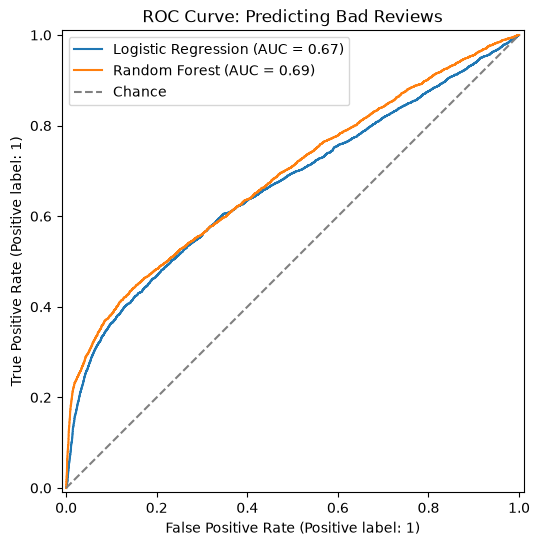

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name="Logistic Regression", ax=ax)
RocCurveDisplay.from_predictions(y_test, y_proba_rf, name="Random Forest", ax=ax)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set_title("ROC Curve: Predicting Bad Reviews")
ax.legend()
plt.savefig("plots/roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

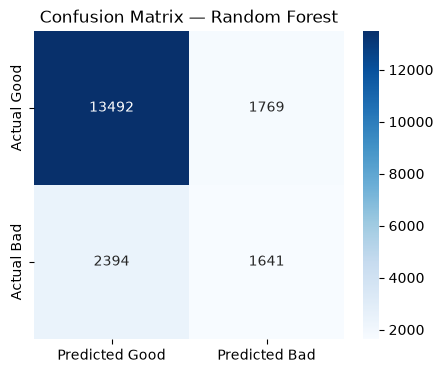

In [9]:
cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Good", "Predicted Bad"],
            yticklabels=["Actual Good", "Actual Bad"])
plt.title("Confusion Matrix — Random Forest")
plt.savefig("plots/confusion_matrix_random_forest.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Explainability with SHAP

A prediction nobody can explain isn't very useful. SHAP shows how much each feature pushed a prediction toward "bad" or "good" review.
Two plots: a summary plot (which features matter most, across all orders) and a bar plot (same info, simpler to read).
I ran this on a sample of 2,000 orders instead of the full test set normal practice for SHAP on Random Forest, since it can be slow on large
data. The overall pattern doesn't really change, it just runs faster.

In [10]:
import shap

SHAP_SAMPLE_SIZE = 2000

rf_model = rf_pipeline.named_steps["clf"]

X_test_sample = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=RANDOM_STATE)
X_test_transformed = rf_pipeline.named_steps["preprocess"].transform(X_test_sample)

if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()
X_test_transformed = np.asarray(X_test_transformed, dtype=np.float64)

# Get feature names after one-hot encoding, for readable SHAP plots
feature_names = (
    feature_cols_numeric
    + list(rf_pipeline.named_steps["preprocess"]
           .named_transformers_["cat"]
           .get_feature_names_out(feature_cols_categorical))
)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_transformed)

if isinstance(shap_values, list):
    sv = shap_values[1]
elif shap_values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

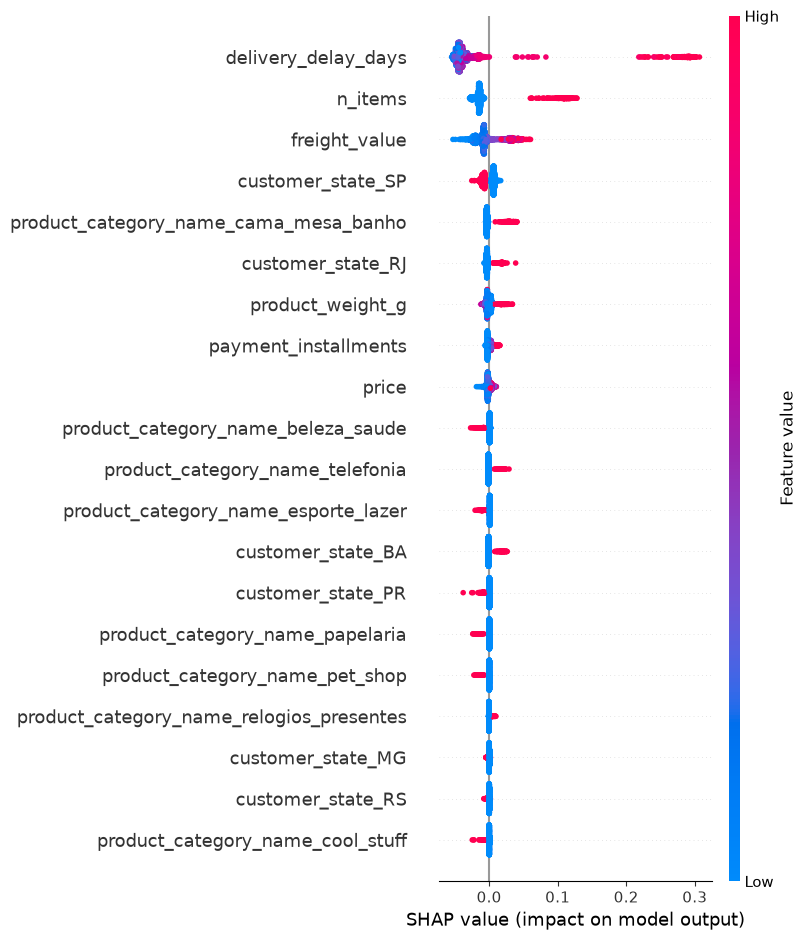

<Figure size 640x480 with 0 Axes>

In [11]:
shap.summary_plot(sv, X_test_transformed, feature_names=feature_names, show=False)
plt.savefig("plots/shap_summary.png", dpi=300, bbox_inches="tight")

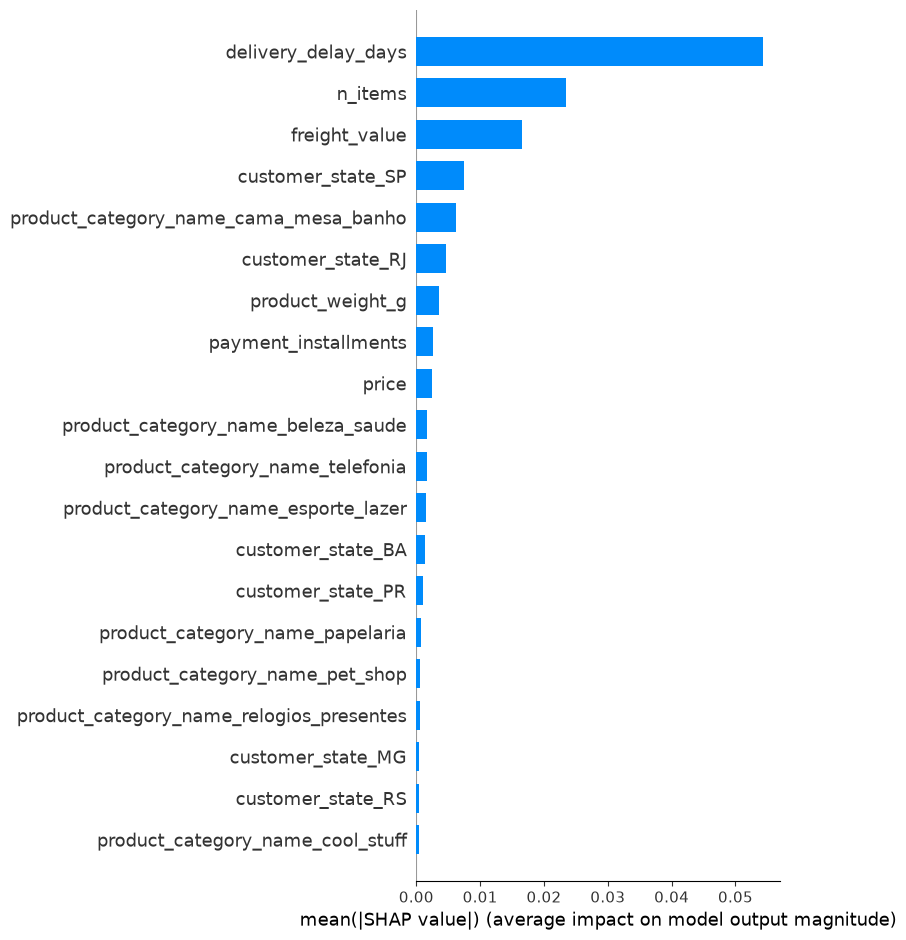

<Figure size 640x480 with 0 Axes>

In [12]:
shap.summary_plot(sv, X_test_transformed, feature_names=feature_names, plot_type="bar", show=False)
plt.savefig("plots/shap_feature_importance.png", dpi=300, bbox_inches="tight")

## 8. Explaining one prediction using SHAP

The summary plot shows what matters on average. But in practice, support would want to know why this one order was flagged. This plot
picks a single test-set order and shows exactly which features pushed it toward "bad" or "good" review, the part that makes the model usable day to day.

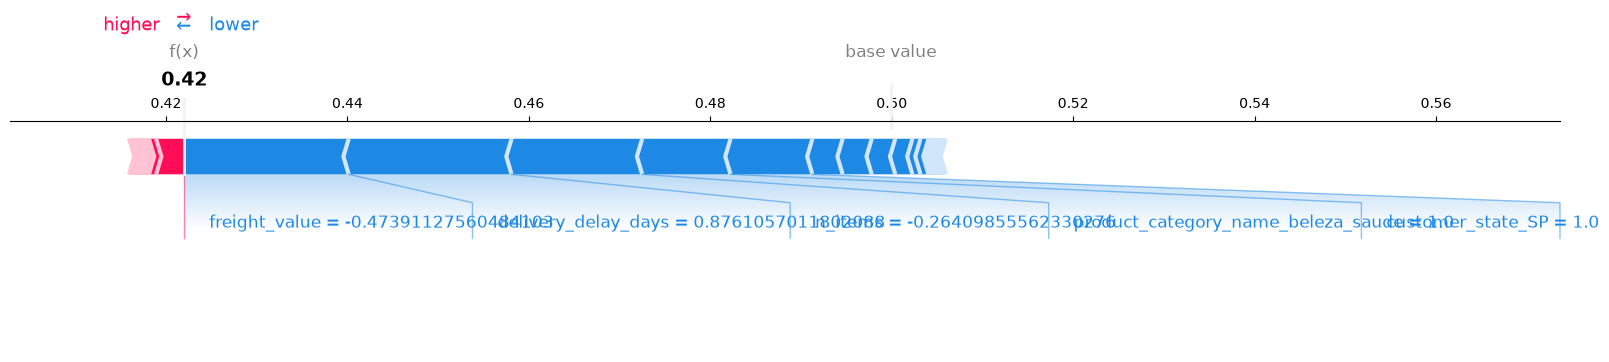

In [13]:
i = 0
shap.initjs()

expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = np.asarray(expected_value).flatten()[-1]

shap.force_plot(
    expected_value,
    sv[i, :],
    X_test_transformed[i, :],
    feature_names=feature_names,
    matplotlib=True,
)